In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
ads = pd.read_csv("../data/Ad_table.csv")

C:\Users\jchmo\AppData\Local\Temp\ipykernel_63180\4006633679.py:1: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  ads = pd.read_csv("../data/Ad_table.csv")


In [9]:
def brand(m):
    m = str(m).upper()
    if "BMW" in m: return "BMW"
    if "AUDI" in m: return "Audi"
    if "MERCEDES" in m: return "Mercedes"
    return None

In [10]:
cmp = ads.copy()
cmp["brand"] = cmp["Maker"].apply(brand)
cmp = cmp.dropna(subset=["brand"])

In [11]:
cmp["car_age"] = cmp["Adv_year"] - cmp["Reg_year"]
cmp["Price"] = pd.to_numeric(cmp["Price"], errors="coerce")
cmp = cmp[cmp["car_age"].between(0, 15) & (cmp["Price"] > 500)]

In [12]:
print(cmp["brand"].value_counts())
print(cmp["Bodytype"].value_counts().head(10))   # check the body type names

brand
Audi        22182
BMW         15743
Mercedes     8334
Name: count, dtype: int64
Bodytype
SUV            13771
Hatchback       9006
Saloon          7270
Coupe           6339
Convertible     4685
Estate          4081
MPV              831
Pickup            69
Limousine         59
Minibus           23
Name: count, dtype: int64


In [13]:
# retention helper
def retention(data, group_cols, ages, min_n=30):
    base = data[data["car_age"] <= 1].groupby(group_cols)["Price"].agg(["median", "size"])
    tgt = data[data["car_age"].isin(ages)].groupby(group_cols)["Price"].agg(["median", "size"])
    r = (tgt["median"] / base["median"]) * 100
    r[(base["size"] < min_n) | (tgt["size"] < min_n)] = np.nan
    return r

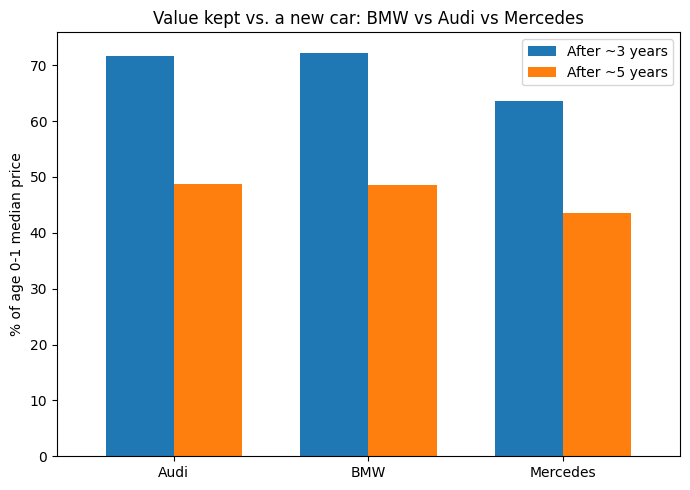

          After ~3 years  After ~5 years
brand                                   
Audi                72.0            49.0
BMW                 72.0            49.0
Mercedes            64.0            44.0


In [17]:
# chart A: overall per brand
overall = pd.DataFrame({
    "After ~3 years": retention(cmp, ["brand"], [2, 3, 4]),
    "After ~5 years": retention(cmp, ["brand"], [4, 5, 6]),
})
ax = overall.plot(kind="bar", figsize=(7, 5), width=0.7)
ax.set(title="Value kept vs. a new car: BMW vs Audi vs Mercedes",
       ylabel="% of age 0-1 median price", xlabel="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/brand_retention_overall.png", dpi=150)
plt.show()
print(overall.round(0))

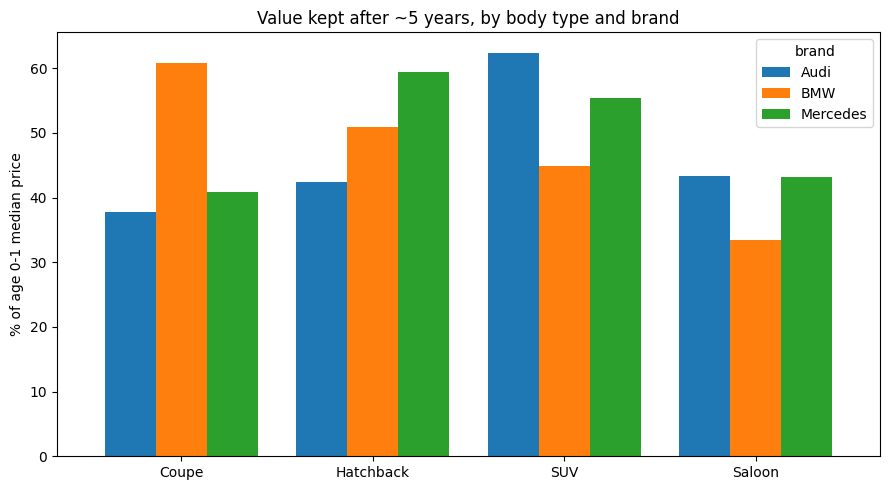

brand      Audi   BMW  Mercedes
Bodytype                       
Coupe      38.0  61.0      41.0
Hatchback  42.0  51.0      59.0
SUV        62.0  45.0      55.0
Saloon     43.0  33.0      43.0


In [16]:
# chart B: per brand within body type (5 years)
top_bodies = cmp["Bodytype"].value_counts().head(4).index
sub = cmp[cmp["Bodytype"].isin(top_bodies)]
by_body = retention(sub, ["Bodytype", "brand"], [4, 5, 6]).unstack("brand")

ax = by_body.plot(kind="bar", figsize=(9, 5), width=0.8)
ax.set(title="Value kept after ~5 years, by body type and brand",
       ylabel="% of age 0-1 median price", xlabel="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/brand_retention_by_body.png", dpi=150)
plt.show()
print(by_body.round(0))